In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move_special import *
import json

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/Explorables/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [2]:
n = 330
Lx = 32
Ly = 32
eta = 0.01
decay_rate = 0.015
eta_special = 0
n_special = 1
t_transient = 200
tmax = 1200

In [3]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

In [ ]:
import csv
import os
import numpy as np
import torch
import random

seeds = [1, 2, 3, 4, 5, 6, 7, 8, 9]

filename = "component_reward_base_330.csv"

# Intestazioni delle colonne
header = [
            "seed", "sim_seed", "n_special", "beta", "delta",
            "n_edges_list", "n_nodes_list", "reward_list", "pop_list", "pod_list"
        ]

if not os.path.exists(filename):
    with open(filename, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(header)

for seed in seeds:
    for i,beta in enumerate(beta_list):
        for j,delta in enumerate(delta_list):

            beta_special = beta
            delta_special = delta
            env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                    beta_special, delta_special, tmax, n_special, t_transient)  
            
            sim_seed = i*len(delta_list) + j + seed*len(beta_list)*len(delta_list)
            np.random.seed(sim_seed)
            random.seed(sim_seed)

            env.reset_objects()
            env.transient()

            n_edges_list = []
            n_nodes_list = []
            rew_list = []
            pop_list = []
            pod_list = []
            
            while env.t < tmax:
                # print(f"Sim {sim_seed}, t={env.t}/{tmax}", end="\r")
                env.update()
                metrics_for_components = env.get_reward()
            
                metrics_for_components = np.array(metrics_for_components)
                n_edges_list.append(metrics_for_components[:,0])
                n_nodes_list.append(metrics_for_components[:,1])
                rew_list.append(metrics_for_components[:,2])
                pop_list.append(env.order_parameter_s().copy())
                pod_list.append(env.order_parameter_p().copy())

            print(delta, beta)

            row_data = [
                seed, sim_seed, n_special, beta, delta,
                n_edges_list, n_nodes_list, rew_list, pop_list, pod_list
            ]

            # Scriviamo direttamente nel CSV
            row_data = [
                seed, sim_seed, n_special, env.beta[-1], env.delta[-1],
                json.dumps([np.asarray(x).tolist() for x in n_edges_list]),
                json.dumps([np.asarray(x).tolist() for x in n_nodes_list]),
                json.dumps([np.asarray(x).tolist() for x in rew_list]),
                json.dumps(pop_list),
                json.dumps(pod_list)
            ]

            with open(filename, "a", newline="") as f:
                        writer = csv.writer(f)
                        writer.writerow(row_data)

    print(f"Risultati salvati per seed {seed}")

0.3 3.5
0.4 3.5
0.5 3.5
0.6 3.5
0.7 3.5
0.8 3.5
0.3 4.5
0.4 4.5
0.5 4.5
0.6 4.5
0.7 4.5
0.8 4.5
0.3 5.5
0.4 5.5
0.5 5.5
0.6 5.5
0.7 5.5
0.8 5.5
0.3 6.5
0.4 6.5
0.5 6.5
0.6 6.5
0.7 6.5
0.8 6.5
0.3 7.5
0.4 7.5
0.5 7.5
0.6 7.5
0.7 7.5
0.8 7.5
0.3 8.5
0.4 8.5
0.5 8.5
0.6 8.5
0.7 8.5
0.8 8.5
0.3 9.5
0.4 9.5
0.5 9.5
0.6 9.5
0.7 9.5
0.8 9.5
Risultati salvati per seed 1
0.3 3.5
0.4 3.5
0.5 3.5
0.6 3.5
0.7 3.5
0.8 3.5
0.3 4.5
0.4 4.5
0.5 4.5
0.6 4.5
0.7 4.5
0.8 4.5
0.3 5.5
0.4 5.5
0.5 5.5
0.6 5.5
0.7 5.5
0.8 5.5
0.3 6.5
0.4 6.5
0.5 6.5
0.6 6.5
0.7 6.5
0.8 6.5
0.3 7.5
0.4 7.5
0.5 7.5
0.6 7.5
0.7 7.5
0.8 7.5
0.3 8.5
0.4 8.5
0.5 8.5
0.6 8.5
0.7 8.5
0.8 8.5
0.3 9.5
0.4 9.5
0.5 9.5
0.6 9.5
0.7 9.5
0.8 9.5
Risultati salvati per seed 2
0.3 3.5
0.4 3.5
0.5 3.5
0.6 3.5
0.7 3.5
0.8 3.5
0.3 4.5
0.4 4.5
0.5 4.5
0.6 4.5
0.7 4.5
0.8 4.5
0.3 5.5
0.4 5.5
0.5 5.5
0.6 5.5
0.7 5.5
0.8 5.5
0.3 6.5
0.4 6.5
0.5 6.5
0.6 6.5
0.7 6.5
0.8 6.5
0.3 7.5
0.4 7.5
0.5 7.5
0.6 7.5
0.7 7.5
0.8 7.5
0.3 8.5
0.4 8.5
0.5 8.5
0.6 8.

In [4]:
# load the dataset
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
load = True
if load:
    dfbm = pd.read_csv("component_reward_base.csv")
    dfbm['n_edges_list'] = dfbm['n_edges_list'].apply(json.loads)
    dfbm['n_nodes_list'] = dfbm['n_nodes_list'].apply(json.loads)
    dfbm['pop_list'] = dfbm['pop_list'].apply(json.loads)
    dfbm['pod_list'] = dfbm['pod_list'].apply(json.loads)
    dfbm['reward_list'] = dfbm['reward_list'].apply(json.loads)

In [5]:
dfbm['how_many_components'] = dfbm['n_edges_list'].apply(lambda x: [len(edges) for edges in x])

In [6]:
dfbm['len_rew'] = dfbm.apply(lambda row: [[min(row['n_nodes_list'][k][i],Lx)/Lx for i in range(len(row['n_nodes_list'][k]))] for k in range(len(row['n_nodes_list']))], axis=1)

In [7]:
dfbm['edge_pen'] = dfbm.apply(lambda row: [-np.array(row['n_edges_list'][k]) / (np.array(row['n_nodes_list'][k]) - 1) for k in range(len(row['n_nodes_list']))], axis=1)

In [8]:
r1_results = np.zeros((len(dfbm), len(dfbm['n_edges_list'][0])))
for c in range(len(dfbm)):
    for i in range(len(dfbm['n_edges_list'][c])):
        pop = dfbm['pop_list'][c][i]
        pod = dfbm['pod_list'][c][i]
        sum_r1 = 0
        for k in range(len(dfbm['n_nodes_list'][c][i])):
            edge_pen = -dfbm['n_edges_list'][c][i][k] / (dfbm['n_nodes_list'][c][i][k] - 1)
            len_rew = min(dfbm['n_nodes_list'][c][i][k], Lx) / Lx
            reward1 = edge_pen + (len_rew*pop + pod)/2
            sum_r1 += reward1
        r1_results[c][i] = sum_r1

In [9]:
dfbm['reward1'] = dfbm.apply(lambda row: [np.sum(row['edge_pen'][i]) + \
                  0.5*row['pop_list'][i]*np.sum(row['len_rew'][i]) + \
                  0.5*row['pod_list'][i]*row['how_many_components'][i] for i in range(len(row['edge_pen']))], axis=1)

dfbm['reward2'] = dfbm.apply(lambda row: [np.sum(row['edge_pen'][i]) + \
                  0.5*(row['pop_list'][i] + row['pod_list'][i]) for i in range(len(row['edge_pen']))], axis=1)

dfbm['reward3'] = dfbm.apply(lambda row: [np.sum(row['edge_pen'][i]) + \
                  0.5 * row['how_many_components'][i] * (row['pop_list'][i]*min(Lx,
                                                                           min(row['n_nodes_list'][i]))/Lx + \
                  row['pod_list'][i]) for i in range(len(row['edge_pen']))], axis=1)

dfbm['reward4'] = dfbm.apply(lambda row: [np.sum(row['edge_pen'][i]) + \
                  0.5 * row['how_many_components'][i] * (row['pop_list'][i]*min(Lx,
                                                            np.array(row['n_nodes_list'][i]).mean())/Lx + \
                  row['pod_list'][i]) for i in range(len(row['edge_pen']))], axis=1)

In [10]:
dfbm['reward'] = dfbm.apply(lambda row: [np.sum(row['reward_list'][i]) for i in range(len(row['reward_list']))], axis=1)

In [11]:
dfbm['r2_mean'] = dfbm['reward2'].apply(lambda x: np.mean(x))
dfbm['r2_mean_50'] = dfbm['reward2'].apply(lambda x: np.mean(x[-50:]))
dfbm['pop_last'] = dfbm['pop_list'].apply(lambda x: x[-1])
dfbm['pod_last'] = dfbm['pod_list'].apply(lambda x: x[-1])
dfbm['r1_mean'] = dfbm['reward1'].apply(lambda x: np.mean(x))
dfbm['r1_mean_50'] = dfbm['reward1'].apply(lambda x: np.mean(x[-50:]))
dfbm['r3_mean'] = dfbm['reward3'].apply(lambda x: np.mean(x))
dfbm['r3_mean_50'] = dfbm['reward3'].apply(lambda x: np.mean(x[-50:]))
dfbm['r4_mean'] = dfbm['reward4'].apply(lambda x: np.mean(x))
dfbm['r4_mean_50'] = dfbm['reward4'].apply(lambda x: np.mean(x[-50:]))

In [12]:
dfbm['r4_mean_50'].shape

(420,)

In [13]:
print('avg r1', dfbm['r1_mean'].mean())
print('avg r1 last 50', dfbm['r1_mean_50'].mean())

print('avg r3', dfbm['r3_mean'].mean())
print('avg r3 last 50', dfbm['r3_mean_50'].mean())

print('avg r4', dfbm['r4_mean'].mean())
print('avg r4 last 50', dfbm['r4_mean_50'].mean()) 
print("stdev r4 last 50", dfbm['r4_mean_50'].std())

avg r1 -7.879555052325908
avg r1 last 50 -6.299293672155806
avg r3 -8.182183786119133
avg r3 last 50 -6.568450786121054
avg r4 -7.471558381848061
avg r4 last 50 -5.991451659014715
stdev r4 last 50 4.440778345214609


In [14]:
'''# save dfbm['r4_mean_50']
dfbm[['seed', 'beta', 'delta', 'r4_mean_50']].to_csv("r4_mean_50_.csv", index=False)
'''
# save pop and pod
dfbm[['seed', 'beta', 'delta', 'pop_last', 'pod_last']].to_csv("pop_pod_last_enh.csv", index=False)

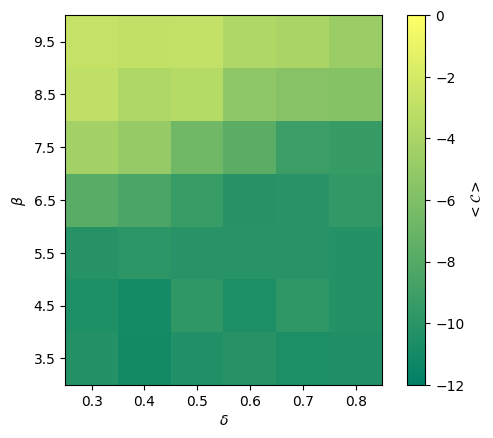

In [15]:
import matplotlib.pyplot as plt
min_val = -12
max_val = 0
rew0 = dfbm['r1_mean'].to_numpy().reshape(10,len(beta_list), len(delta_list)).mean(axis=0)
plt.imshow(rew0, cmap='summer', origin='lower', vmin=min_val, vmax=max_val)
plt.colorbar(label=r'$<\mathcal{C}>$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
# plt.title(r' $<r>_{50}$ for 30 enchanced abm ants')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

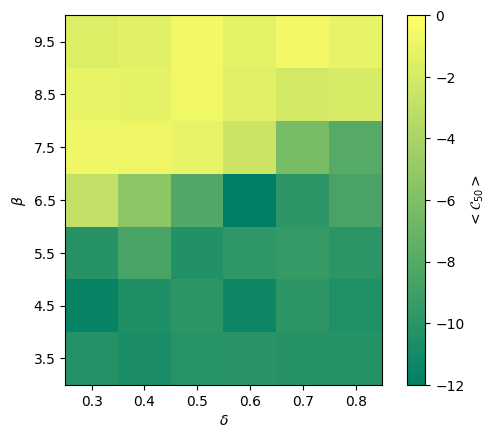

In [16]:
import matplotlib.pyplot as plt
min_val = -12
max_val = 0
rew0 = dfbm['r1_mean_50'].to_numpy().reshape(10,len(beta_list), len(delta_list)).mean(axis=0)
plt.imshow(rew0, cmap='summer', origin='lower', vmin=min_val, vmax=max_val)
plt.colorbar(label=r'$<\mathcal{C}_{50}>$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
# plt.title(r' $<r>_{50}$ for 30 enchanced abm ants')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

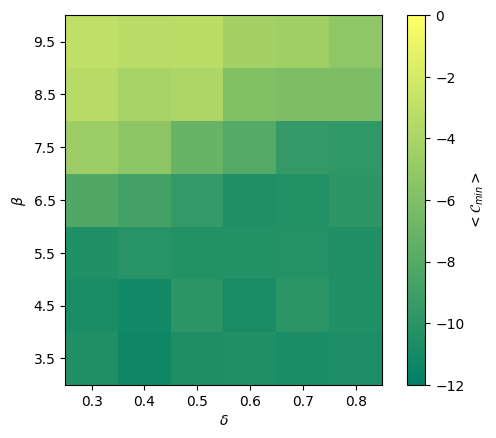

In [17]:
import matplotlib.pyplot as plt
min_val = -12
max_val = 0
rew0 = dfbm['r3_mean'].to_numpy().reshape(10,len(beta_list), len(delta_list)).mean(axis=0)
plt.imshow(rew0, cmap='summer', origin='lower', vmin=min_val, vmax=max_val)
plt.colorbar(label=r'$<\mathcal{C}_{min}>$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
# plt.title(r' $<r>_{50}$ for 30 enchanced abm ants')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

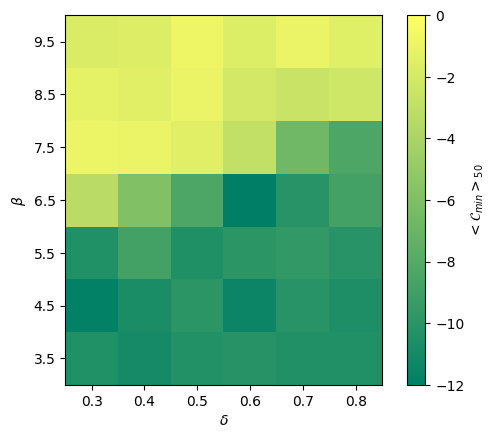

In [18]:
import matplotlib.pyplot as plt
min_val = -12
max_val = 0
rew0 = dfbm['r3_mean_50'].to_numpy().reshape(10,len(beta_list), len(delta_list)).mean(axis=0)
plt.imshow(rew0, cmap='summer', origin='lower', vmin=min_val, vmax=max_val)
plt.colorbar(label=r'$<\mathcal{C}_{min}>_{50}$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
# plt.title(r' $<r>_{50}$ for 30 enchanced abm ants')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

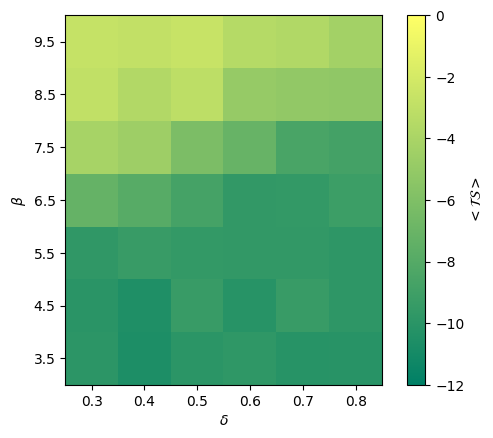

In [19]:
import matplotlib.pyplot as plt
min_val = -12
max_val = 0
rew0 = dfbm['r4_mean'].to_numpy().reshape(10,len(beta_list), len(delta_list)).mean(axis=0)
plt.imshow(rew0, cmap='summer', origin='lower', vmin=min_val, vmax=max_val)
plt.colorbar(label=r'$<\mathcal{TS}>$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
# plt.title(r' $<r>_{50}$ for 30 enchanced abm ants')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

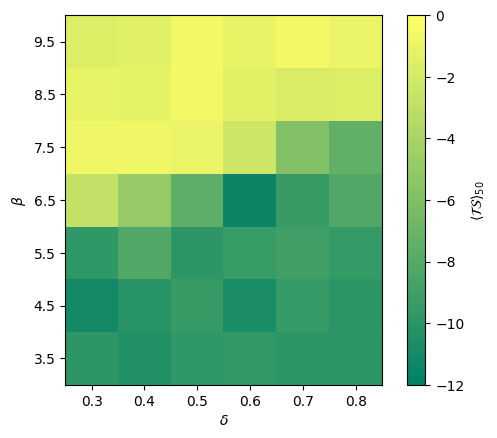

In [22]:
import matplotlib.pyplot as plt
min_val = -12
max_val = 0
rew0 = dfbm['r4_mean_50'].to_numpy().reshape(10,len(beta_list), len(delta_list)).mean(axis=0)
plt.imshow(rew0, cmap='summer', origin='lower', vmin=min_val, vmax=max_val)
plt.colorbar(label=r'$\langle \mathcal{TS} \rangle_{50}$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
# plt.title(r' $<r>_{50}$ for 30 enchanced abm ants')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

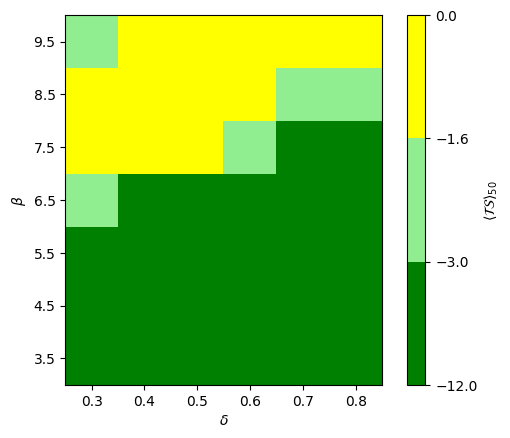

In [24]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Same heatmap data (r4_mean_50), but with threshold-based color clusters
rew0 = dfbm['r4_mean_50'].to_numpy().reshape(10, len(beta_list), len(delta_list)).mean(axis=0)

# Thresholds / bins: [-12,-10), [-10,-6), [-6,-2), [-2,0]
bounds = [-12, -3, -1.6, 0]
# yellow to green
cmap = mcolors.ListedColormap(['green', 'lightgreen', 'yellow'])
norm = mcolors.BoundaryNorm(bounds, cmap.N)

plt.figure()
img = plt.imshow(rew0, cmap=cmap, norm=norm, origin='lower')
cbar = plt.colorbar(img, ticks=bounds)
cbar.set_label(r'$\langle \mathcal{TS} \rangle_{50}$')

plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

In [20]:
import numpy as np
import pandas as pd

beta_desc = sorted(beta_list, reverse=True)
pivot_r4_50 = (
    dfbm.groupby(['beta', 'delta'])['pod_last']
        .mean()
        .unstack('delta')
        .reindex(index=beta_desc, columns=delta_list)
)

latex_lines = []
latex_lines.append(r"\begin{table}[h]")
latex_lines.append(r"\centering")
latex_lines.append(r"\begin{tabular}{c" + "r" * len(delta_list) + r"}")  # no pipes
latex_lines.append(r"\toprule")
latex_lines.append(
    r"\diagbox[innerwidth=1.6cm]{$\beta$}{$\delta$} & "
    + " & ".join([f"${d}$" for d in delta_list])
    + r" \\"
)
latex_lines.append(r"\midrule")
for beta in beta_desc:
    row_vals = [f"{pivot_r4_50.loc[beta, delta]:.2f}" for delta in delta_list]
    latex_lines.append(f"${beta}$ & " + " & ".join(row_vals) + r" \\")  # row ending
latex_lines.append(r"\bottomrule")
latex_lines.append(r"\end{tabular}%")
latex_lines.append(r"\caption{$\langle\mathcal{TS}\rangle_{50}$}")
latex_lines.append(r"\label{tab:r4_mean}")
latex_lines.append(r"\end{table}")

latex_table_r4_50 = "\n".join(latex_lines)
print(latex_table_r4_50)

\begin{table}[h]
\centering
\begin{tabular}{crrrrrr}
\toprule
\diagbox[innerwidth=1.6cm]{$\beta$}{$\delta$} & $0.3$ & $0.4$ & $0.5$ & $0.6$ & $0.7$ & $0.8$ \\
\midrule
$9.5$ & 1.00 & 0.99 & 0.99 & 0.98 & 0.96 & 0.98 \\
$8.5$ & 1.00 & 0.99 & 0.98 & 0.99 & 0.90 & 0.85 \\
$7.5$ & 0.99 & 0.95 & 0.87 & 0.83 & 0.64 & 0.34 \\
$6.5$ & 0.93 & 0.82 & 0.57 & 0.29 & 0.19 & 0.20 \\
$5.5$ & 0.28 & 0.19 & 0.20 & 0.17 & 0.21 & 0.21 \\
$4.5$ & 0.20 & 0.18 & 0.18 & 0.19 & 0.21 & 0.20 \\
$3.5$ & 0.19 & 0.24 & 0.20 & 0.18 & 0.18 & 0.21 \\
\bottomrule
\end{tabular}%
\caption{$\langle\mathcal{TS}\rangle_{50}$}
\label{tab:r4_mean}
\end{table}


In [18]:
dfbm.head()

,seed,sim_seed,n_special,beta,delta,n_edges_list,n_nodes_list,reward_list,pop_list,pod_list,...,r2_mean,r2_mean_50,pop_last,pod_last,r1_mean,r1_mean_50,r3_mean,r3_mean_50,r4_mean,r4_mean_50
0,1,42,1,3.5,0.3,"[[452.0, 239.0, 264.0, 26.0, 1.0, 3.0, 7.0, 1....","[[199.0, 107.0, 121.0, 13.0, 2.0, 3.0, 6.0, 2....","[[-2.1023712541938675, -2.07425995249766, -2.0...","[0.17303526939004324, 0.17311667610495118, 0.1...","[0.18787878787878787, 0.18787878787878787, 0.1...",...,-12.194986,-11.543060,0.159201,0.181818,-11.314083,-10.703080,-11.497350,-10.842761,-10.859878,-10.183944
1,1,43,1,3.5,0.4,"[[941.0, 93.0, 66.0, 4.0, 12.0, 8.0, 2.0, 8.0,...","[[379.0, 47.0, 34.0, 4.0, 8.0, 6.0, 3.0, 6.0, ...","[[-2.245395218744305, -1.7777163597610985, -1....","[0.17895463225645905, 0.1779755316457271, 0.17...","[0.3090909090909091, 0.2909090909090909, 0.260...",...,-9.621430,-9.216210,0.158419,0.200000,-8.950100,-8.682380,-9.103717,-8.855064,-8.584698,-8.412380
2,1,44,1,3.5,0.5,"[[130.0, 1030.0, 16.0, 8.0, 2.0, 2.0, 1.0], [1...","[[69.0, 403.0, 13.0, 7.0, 3.0, 3.0, 2.0], [74....","[[-1.7389993631135048, -2.38942371195752, -1.2...","[0.17583371584072693, 0.16851890278740686, 0.1...","[0.1696969696969697, 0.13333333333333333, 0.28...",...,-9.860065,-7.957566,0.163182,0.181818,-9.149394,-7.418701,-9.306932,-7.525710,-8.796778,-7.118074
3,1,45,1,3.5,0.6,"[[1032.0, 23.0, 1.0, 1.0, 1.0, 1.0, 2.0], [101...","[[447.0, 20.0, 2.0, 2.0, 2.0, 2.0, 3.0], [440....","[[-2.1333273111590536, -1.061303908093071, -0....","[0.1672086743254583, 0.16524196429154214, 0.16...","[0.19393939393939394, 0.19393939393939394, 0.2...",...,-13.018377,-11.673104,0.155877,0.187879,-12.095119,-10.828273,-12.303258,-11.024688,-11.640683,-10.468893
4,1,46,1,3.5,0.7,"[[1066.0, 34.0, 2.0, 2.0, 12.0, 3.0, 1.0, 1.0]...","[[443.0, 17.0, 3.0, 3.0, 9.0, 3.0, 2.0, 2.0], ...","[[-2.249850466010178, -2.000630787340634, -0.9...","[0.16019211610798625, 0.15972413065662833, 0.1...","[0.16363636363636364, 0.20606060606060606, 0.2...",...,-11.843512,-10.102661,0.145195,0.218182,-11.032472,-9.486780,-11.182341,-9.628595,-10.581755,-9.140986
